In [29]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict

In [30]:
class DiscountState(TypedDict):
    total: float
    discount_rate: float
    final_price: float

In [31]:
def apply_discount(state: DiscountState) :
    total = state['total']
    rate = state['discount_rate']
    final = total * (1 - rate)
    return {'final_price': final}

In [32]:
def check_eligibility(state: DiscountState) :
    total = state['total']
    
    if total >= 1000:
        return {'discount_rate':0.20}
    elif total >= 500:
        return {'discount_rate':0.10}
    else:
        return {'discount_rate':0.0}
        

In [33]:
def no_discount(state: DiscountState) :
    return {'final_price': state['total']}

In [34]:
def router_discount(state: DiscountState):  # Router function
    if state['discount_rate'] > 0:
        return 'apply_discount'
    else:
        return 'no_discount'
    

In [35]:
graph = StateGraph(DiscountState)

graph.add_node("check_eligibility",check_eligibility)

graph.add_node("apply_discount",apply_discount)

graph.add_node("no_discount",no_discount)




graph.add_edge( START,"check_eligibility" )

#graph.add_conditional_edges("check_eligibility",router_discount)

graph.add_conditional_edges("check_eligibility",router_discount,{
    "apply_discount": "apply_discount",
    "no_discount": "no_discount"
})

graph.add_edge("apply_discount", END)

graph.add_edge("no_discount", END)


In [36]:
workflow = graph.compile()

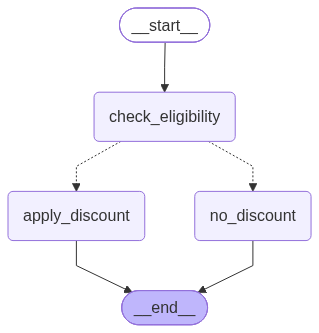

In [37]:
workflow

In [ ]:
response = workflow.invoke({'total': 1000.0})

In [39]:
print(response)

{'total': 200.0, 'discount_rate': 0.0, 'final_price': 200.0}
